In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Model-1(ResNet)

In [26]:
import os
import json
import numpy as np
from PIL import Image, ImageDraw

DATASET_PATH = "/kaggle/input/datasets/vesusve/india-driving-dataset-idd/idd-segmentation/IDD_Segmentation"
TRAIN_GT_PATH = os.path.join(DATASET_PATH, "gtFine", "train")
VAL_GT_PATH = os.path.join(DATASET_PATH, "gtFine", "val")
TRAIN_IMG_PATH = os.path.join(DATASET_PATH, "leftImg8bit", "train")
VAL_IMG_PATH = os.path.join(DATASET_PATH, "leftImg8bit", "val")

labels_list = [
    "out of roi", "animal", "autorickshaw", "bicycle", "billboard", "bridge", 
    "building", "bus", "car", "caravan", "curb", "drivable fallback", 
    "fallback background", "fence", "guard rail", "license plate", "motorcycle", 
    "non-drivable fallback", "obs-str-bar-fallback", "parking", "person", "pole", 
    "polegroup", "rail track", "rectification border", "rider", "road", "sidewalk", 
    "sky", "traffic light", "traffic sign", "trailer", "train", "truck", 
    "tunnel", "vegetation", "vehicle fallback", "wall"
]

label_to_idx = {label: idx for idx, label in enumerate(labels_list)}

def generate_mask_from_json(json_path):
    with open(json_path, 'r') as f:
        data = json.load(f)
    
    height = data['imgHeight']
    width = data['imgWidth']
    
    temp_img = Image.new("L", (width, height), 0)
    draw = ImageDraw.Draw(temp_img)
    
    for obj in data['objects']:
        label = obj['label']
        polygon = obj['polygon']
        flat_coords = [coord for pt in polygon for coord in pt]
        if len(flat_coords) >= 4:
            class_idx = label_to_idx.get(label, 0)
            draw.polygon(flat_coords, fill=class_idx)
            
    mask = np.array(temp_img, dtype=np.int32)
    return mask

In [27]:
import tensorflow as tf

def get_file_pairs(img_dir, gt_dir):
    img_paths = []
    json_paths = []
    for city in os.listdir(gt_dir):
        city_gt_path = os.path.join(gt_dir, city)
        city_img_path = os.path.join(img_dir, city)
        if os.path.isdir(city_gt_path):
            for file in os.listdir(city_gt_path):
                if file.endswith('_gtFine_polygons.json'):
                    base_name = file.replace('_gtFine_polygons.json', '')
                    json_path = os.path.join(city_gt_path, file)
                    img_path = os.path.join(city_img_path, base_name + '_leftImg8bit.png')
                    if os.path.exists(img_path):
                        img_paths.append(img_path)
                        json_paths.append(json_path)
    return img_paths, json_paths

train_imgs, train_jsons = get_file_pairs(TRAIN_IMG_PATH, TRAIN_GT_PATH)

def load_data(img_path, json_path):
    img_path = img_path.numpy().decode('utf-8')
    json_path = json_path.numpy().decode('utf-8')
    
    image = Image.open(img_path).convert('RGB')
    image = image.resize((512, 256))
    image = np.array(image, dtype=np.float32) / 255.0
    
    mask = generate_mask_from_json(json_path)
    mask = Image.fromarray(mask.astype(np.uint8))
    mask = mask.resize((512, 256), Image.NEAREST)
    mask = np.array(mask, dtype=np.int32)
    mask = np.expand_dims(mask, axis=-1)
    
    return image, mask

def tf_load_data(img_path, json_path):
    image, mask = tf.py_function(load_data, [img_path, json_path], [tf.float32, tf.int32])
    image.set_shape([256, 512, 3])
    mask.set_shape([256, 512, 1])
    return image, mask

# 1000 images ka sweet spot jo fast bhi chale aur accuracy bhi de
train_dataset = tf.data.Dataset.from_tensor_slices((train_imgs[:2500], train_jsons[:2500]))
train_dataset = train_dataset.map(tf_load_data, num_parallel_calls=tf.data.AUTOTUNE)
train_dataset = train_dataset.cache()  # Speed double karne ke liye
train_dataset = train_dataset.shuffle(1000).batch(4).prefetch(tf.data.AUTOTUNE)

In [28]:
import tensorflow.keras as keras
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Conv2D, UpSampling2D, Concatenate
from tensorflow.keras.models import Model

def build_resnet_unet(num_classes):
    base_model = ResNet50(input_shape=(256, 512, 3), include_top=False, weights='imagenet')
    
    input_skip = base_model.layers[0].output  # Shape: (256, 512, 3)
    skip_names = ['conv1_relu', 'conv2_block3_out', 'conv3_block4_out', 'conv4_block6_out']
    skips = [input_skip] + [base_model.get_layer(name).output for name in skip_names]
    
    x = base_model.output  # Shape: (8, 16, 2048)
    
    x = UpSampling2D((2, 2))(x)
    x = Concatenate()([x, skips[4]])
    x = Conv2D(256, 3, padding='same', activation='relu')(x)
    
    x = UpSampling2D((2, 2))(x)
    x = Concatenate()([x, skips[3]])
    x = Conv2D(128, 3, padding='same', activation='relu')(x)
    
    x = UpSampling2D((2, 2))(x)
    x = Concatenate()([x, skips[2]])
    x = Conv2D(64, 3, padding='same', activation='relu')(x)
    
    x = UpSampling2D((2, 2))(x)
    x = Concatenate()([x, skips[1]])
    x = Conv2D(32, 3, padding='same', activation='relu')(x)
    
    # 5th UpSampling to bring back to original (256, 512)
    x = UpSampling2D((2, 2))(x)
    x = Concatenate()([x, skips[0]])
    x = Conv2D(16, 3, padding='same', activation='relu')(x)
    
    outputs = Conv2D(num_classes, 1, padding='same', activation='softmax')(x)
    
    model = Model(inputs=base_model.input, outputs=outputs)
    return model

strategy = tf.distribute.MirroredStrategy()
print(f"Number of devices: {strategy.num_replicas_in_sync}")

with strategy.scope():
    model = build_resnet_unet(len(labels_list))
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
Number of devices: 2


In [29]:
history = model.fit(
    train_dataset,
    epochs=7,
    verbose=1
)

Epoch 1/7
INFO:tensorflow:Collective all_reduce tensors: 224 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
625/625 ━━━━━━━━━━━━━━━━━━━━ 432s 566ms/step - accuracy: 0.5816 - loss: 1.5608
Epoch 2/7
625/625 ━━━━━━━━━━━━━━━━━━━━ 144s 231ms/step - accuracy: 0.7118 - loss: 0.9989
Epoch 3/7
625/625 ━━━━━━━━━━━━━━━━━━━━ 144s 230ms/step - accuracy: 0.7397 - loss: 0.8741
Epoch 4/7
625/625 ━━━━━━━━━━━━━━━━━━━━ 144s 229ms/step - accuracy: 0.7602 - loss: 0.7881
Epoch 5/7
625/625 ━━━━━━━━━━━━━━━━━━━━ 144s 229ms/step - accuracy: 0.7708 - loss: 0.7452
Epoch 6/7
625/625 ━━━━━━━━━━━━━━━━━━━━ 143s 229ms/step - accuracy: 0.7829 - loss: 0.7020
Epoch 7/7
625/625 ━━━━━━━━━━━━━━━━━━━━ 144s 230ms/step - accuracy: 0.7943 - loss: 0.6625


In [30]:
import tensorflow.keras as keras

# Recompile inside the strategy scope so the distributed setup matches
with strategy.scope():
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

history_extended = model.fit(
    train_dataset,
    initial_epoch=7,
    epochs=10,
    verbose=1
)

Epoch 8/10
INFO:tensorflow:Collective all_reduce tensors: 224 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
625/625 ━━━━━━━━━━━━━━━━━━━━ 185s 231ms/step - accuracy: 0.8260 - loss: 0.5526
Epoch 9/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 144s 230ms/step - accuracy: 0.8356 - loss: 0.5226
Epoch 10/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 144s 230ms/step - accuracy: 0.8419 - loss: 0.5024


In [31]:
history_extended = model.fit(
    train_dataset,
    initial_epoch=10,
    epochs=15,
    verbose=1
)

Epoch 11/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 145s 231ms/step - accuracy: 0.8478 - loss: 0.4855
Epoch 12/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 144s 231ms/step - accuracy: 0.8526 - loss: 0.4701
Epoch 13/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 144s 231ms/step - accuracy: 0.8576 - loss: 0.4550
Epoch 14/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 144s 230ms/step - accuracy: 0.8625 - loss: 0.4411
Epoch 15/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 144s 231ms/step - accuracy: 0.8666 - loss: 0.4275


In [32]:
import tensorflow.keras as keras

with strategy.scope():
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=5e-5),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

history_90 = model.fit(
    train_dataset,
    initial_epoch=15,
    epochs=25,
    verbose=1
)

Epoch 16/25
INFO:tensorflow:Collective all_reduce tensors: 224 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1
625/625 ━━━━━━━━━━━━━━━━━━━━ 184s 230ms/step - accuracy: 0.8720 - loss: 0.4101
Epoch 17/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 143s 229ms/step - accuracy: 0.8747 - loss: 0.4008
Epoch 18/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 143s 229ms/step - accuracy: 0.8768 - loss: 0.3939
Epoch 19/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 143s 229ms/step - accuracy: 0.8791 - loss: 0.3870
Epoch 20/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 143s 228ms/step - accuracy: 0.8812 - loss: 0.3793
Epoch 21/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 142s 228ms/step - accuracy: 0.8833 - loss: 0.3720
Epoch 22/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 143s 228ms/step - accuracy: 0.8852 - loss: 0.3657
Epoch 23/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 143s 229ms/step - accuracy: 0.8871 - loss: 0.3600
Epoch 24/25
625/625 ━━━━━━━━━━━━━━━━━━━━ 143s 228ms/step - accuracy: 0.8890 - loss: 0.3534
Epoch 25/25
625/625

In [33]:
model.save('unet_idd_90.keras')

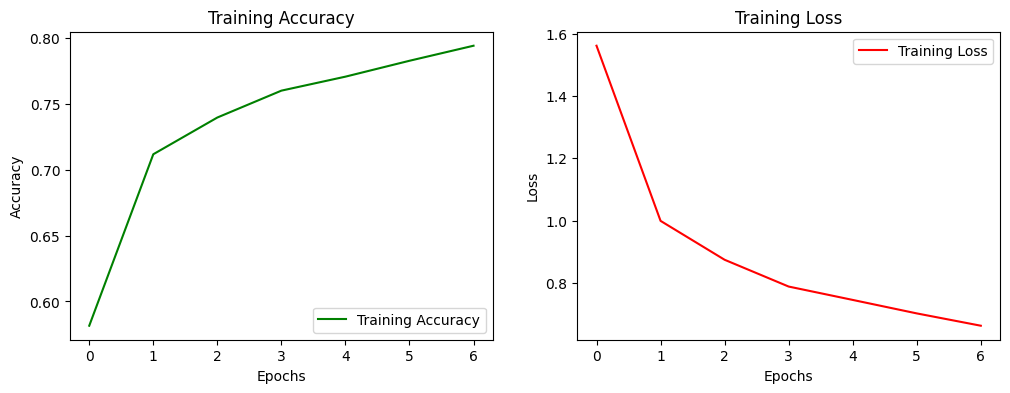

In [34]:
import matplotlib.pyplot as plt

# Agar history alag-alag save ki thi toh unhe combine kar sakte hain, 
# ya jo final 'history' object hai usko plot kar lo:
acc = history.history['accuracy']
loss = history.history['loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', color='green')
plt.title('Training Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', color='red')
plt.title('Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='upper right')

plt.show()

In [37]:
# Validation/Test file pairs get karna
val_imgs, val_jsons = get_file_pairs(VAL_IMG_PATH, VAL_GT_PATH)

# Test dataset build karna
test_dataset = tf.data.Dataset.from_tensor_slices((val_imgs[:500], val_jsons[:500]))
test_dataset = test_dataset.map(tf_load_data, num_parallel_calls=tf.data.AUTOTUNE)
test_dataset = test_dataset.batch(4).prefetch(tf.data.AUTOTUNE)

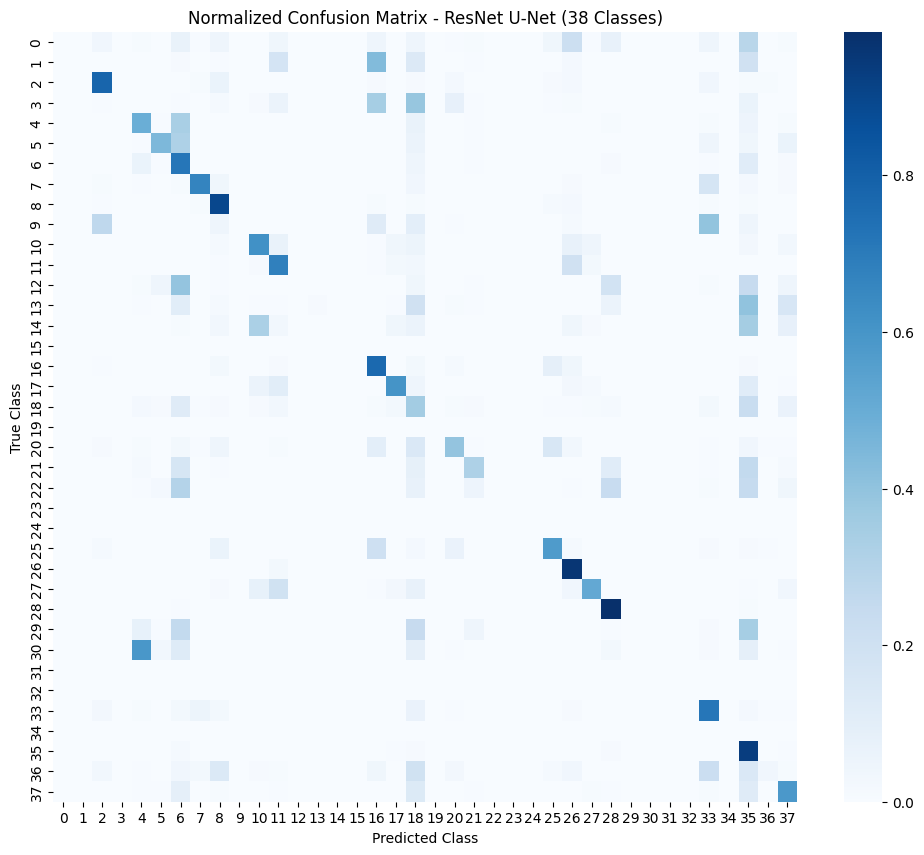

In [38]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm_total = np.zeros((38, 38), dtype=np.int64)

for images, true_masks in test_dataset:
    preds = model.predict(images, verbose=0)
    pred_masks = np.argmax(preds, axis=-1)
    
    y_true = true_masks.numpy().flatten()
    y_pred = pred_masks.flatten()
    
    cm_batch = confusion_matrix(y_true, y_pred, labels=range(38))
    cm_total += cm_batch

cm_norm = cm_total.astype('float') / (cm_total.sum(axis=1, keepdims=True) + 1e-7)

plt.figure(figsize=(12, 10))
sns.heatmap(cm_norm, cmap='Blues')
plt.title('Normalized Confusion Matrix - ResNet U-Net (38 Classes)')
plt.xlabel('Predicted Class')
plt.ylabel('True Class')
plt.show()

# Testing(ResNet)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 550ms/step


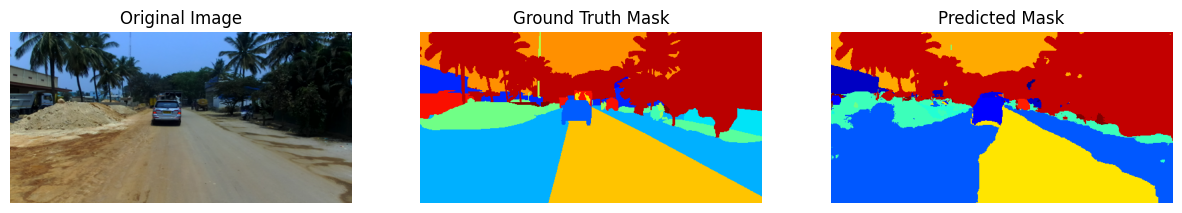

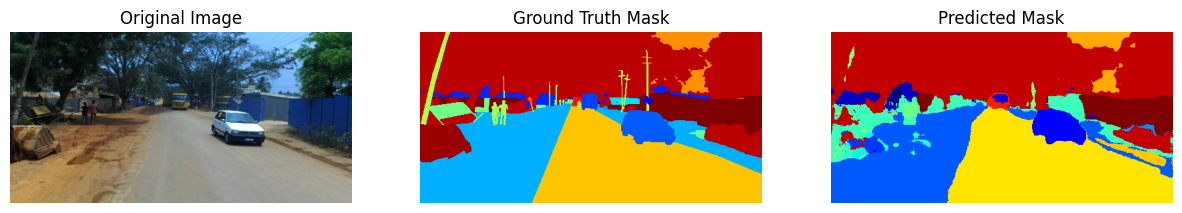

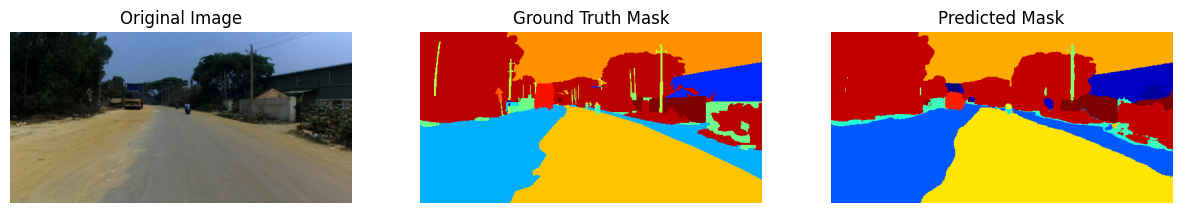

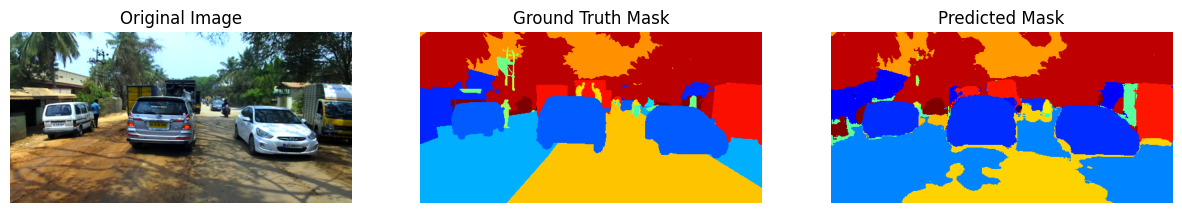

In [39]:
import matplotlib.pyplot as plt
import numpy as np

for images, true_masks in test_dataset.take(1):
    preds = model.predict(images)
    pred_masks = np.argmax(preds, axis=-1)
    
    for i in range(len(images)):
        plt.figure(figsize=(15, 5))
        
        plt.subplot(1, 3, 1)
        plt.imshow(images[i])
        plt.title('Original Image')
        plt.axis('off')
        
        plt.subplot(1, 3, 2)
        plt.imshow(true_masks[i].numpy().squeeze(), cmap='jet')
        plt.title('Ground Truth Mask')
        plt.axis('off')
        
        plt.subplot(1, 3, 3)
        plt.imshow(pred_masks[i], cmap='jet')
        plt.title('Predicted Mask')
        plt.axis('off')
        
        plt.show()

# Model-2 (DeepLabV3+)


In [48]:
import tensorflow as tf

def build_deeplabv3(num_classes=38):
    base_model = tf.keras.applications.ResNet50(
        input_shape=(256, 512, 3), 
        include_top=False, 
        weights='imagenet'
    )
    
    # ResNet50 32x downsample karta hai, isliye 32x upsampling chahiye
    x = base_model.output
    x = tf.keras.layers.Conv2D(256, (3, 3), padding='same', activation='relu')(x)
    x = tf.keras.layers.UpSampling2D(size=(32, 32), interpolation='bilinear')(x)
    outputs = tf.keras.layers.Conv2D(num_classes, (1, 1), padding='same', activation=None)(x)
    
    model = tf.keras.models.Model(inputs=base_model.input, outputs=outputs)
    return model

with strategy.scope():
    deeplab_model = build_deeplabv3(num_classes=38)
    
    optimizer = tf.keras.optimizers.AdamW(learning_rate=1e-4, weight_decay=0.01)
    
    deeplab_model.compile(
        optimizer=optimizer,
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=['accuracy']
    )

# 5 Epochs Training Run
history_deeplab = deeplab_model.fit(
    train_dataset,
    epochs=5,
    verbose=1
)

Epoch 1/5
INFO:tensorflow:Collective all_reduce tensors: 216 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1


E0000 00:00:1792522733.807736      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/SelectV2-1-TransposeNHWCToNCHW-LayoutOptimizer


625/625 ━━━━━━━━━━━━━━━━━━━━ 167s 202ms/step - accuracy: 0.7476 - loss: 0.8472
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 126s 201ms/step - accuracy: 0.8142 - loss: 0.5791
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 125s 200ms/step - accuracy: 0.8409 - loss: 0.4823
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 125s 200ms/step - accuracy: 0.8574 - loss: 0.4244
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 125s 200ms/step - accuracy: 0.8678 - loss: 0.3882


In [49]:
# Epochs 6 to 10 training run
history_deeplab_ext = deeplab_model.fit(
    train_dataset,
    epochs=5,
    verbose=1
)

Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 125s 200ms/step - accuracy: 0.8746 - loss: 0.3625
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 126s 201ms/step - accuracy: 0.8770 - loss: 0.3527
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 125s 201ms/step - accuracy: 0.8824 - loss: 0.3344
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 125s 200ms/step - accuracy: 0.8818 - loss: 0.3356
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 125s 199ms/step - accuracy: 0.8871 - loss: 0.3169


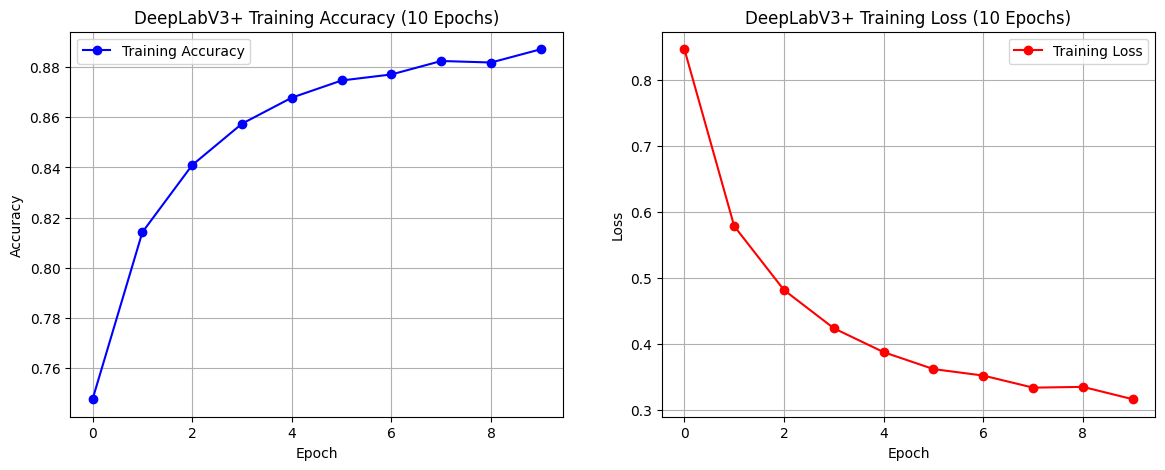

In [51]:
import matplotlib.pyplot as plt

# Dono history ko combine karna (Epochs 1 to 10)
total_acc = history_deeplab.history['accuracy'] + history_deeplab_ext.history['accuracy']
total_loss = history_deeplab.history['loss'] + history_deeplab_ext.history['loss']

plt.figure(figsize=(14, 5))

# Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(total_acc, marker='o', color='blue', label='Training Accuracy')
plt.title('DeepLabV3+ Training Accuracy (10 Epochs)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid(True)
plt.legend()

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(total_loss, marker='o', color='red', label='Training Loss')
plt.title('DeepLabV3+ Training Loss (10 Epochs)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()

plt.show()

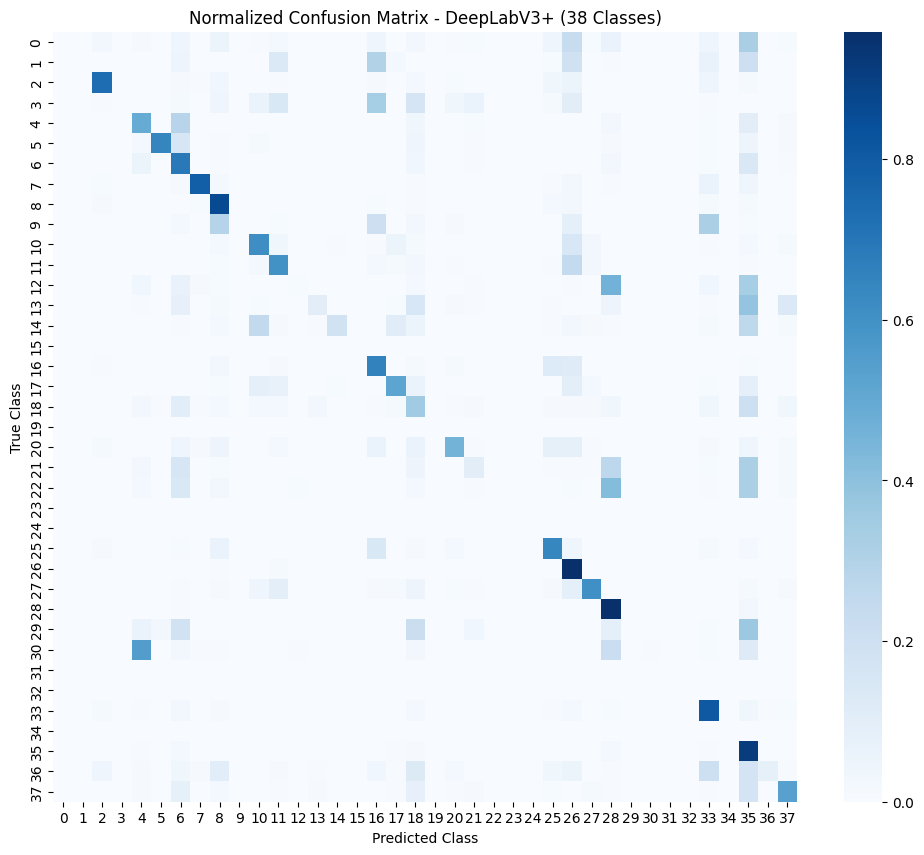

In [52]:
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_total = np.zeros((38, 38), dtype=np.int64)

for images, true_masks in test_dataset:
    preds = deeplab_model.predict(images, verbose=0)
    pred_masks = np.argmax(preds, axis=-1)
    
    y_true = true_masks.numpy().flatten()
    y_pred = pred_masks.flatten()
    
    cm_batch = confusion_matrix(y_true, y_pred, labels=range(38))
    cm_total += cm_batch

cm_norm = cm_total.astype('float') / (cm_total.sum(axis=1, keepdims=True) + 1e-7)

plt.figure(figsize=(12, 10))
sns.heatmap(cm_norm, cmap='Blues')
plt.title('Normalized Confusion Matrix - DeepLabV3+ (38 Classes)')
plt.xlabel('Predicted Class')
plt.ylabel('True Class')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 517ms/step


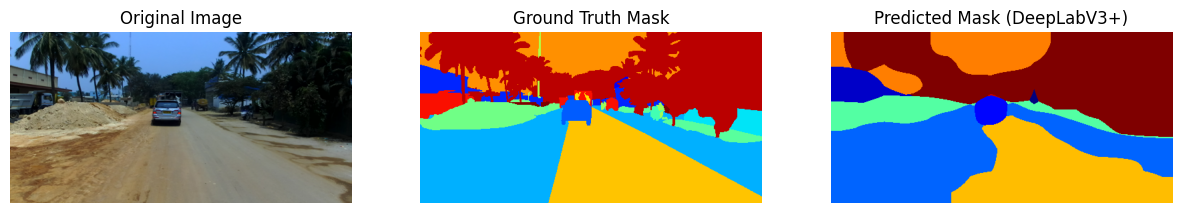

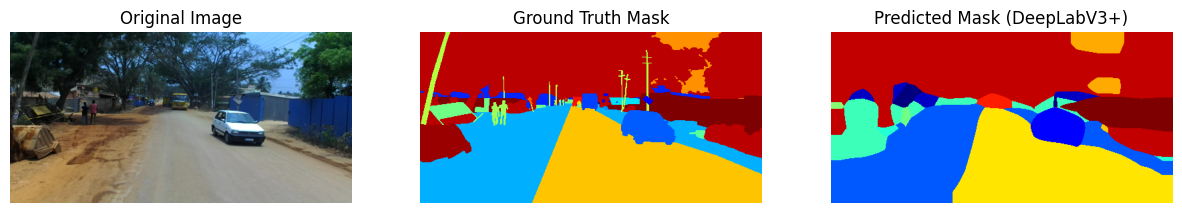

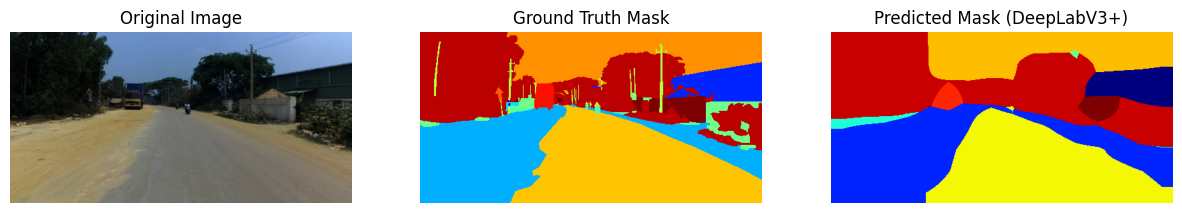

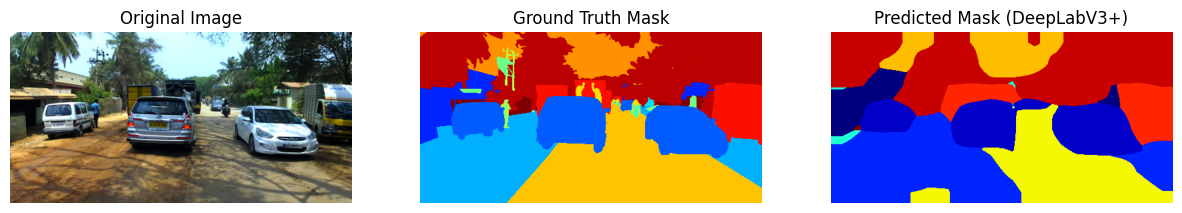

In [53]:
for images, true_masks in test_dataset.take(1):
    preds = deeplab_model.predict(images)
    pred_masks = np.argmax(preds, axis=-1)
    
    for i in range(len(images)):
        plt.figure(figsize=(15, 5))
        
        plt.subplot(1, 3, 1)
        plt.imshow(images[i])
        plt.title('Original Image')
        plt.axis('off')
        
        plt.subplot(1, 3, 2)
        plt.imshow(true_masks[i].numpy().squeeze(), cmap='jet')
        plt.title('Ground Truth Mask')
        plt.axis('off')
        
        plt.subplot(1, 3, 3)
        plt.imshow(pred_masks[i], cmap='jet')
        plt.title('Predicted Mask (DeepLabV3+)')
        plt.axis('off')
        
        plt.show()

In [54]:
deeplab_model.save('deeplab_idd_90.keras')
print("DeepLabV3+ model successfully saved as deeplab_idd_90.keras")

DeepLabV3+ model successfully saved as deeplab_idd_90.keras


# Comparison 

Loading saved models...
Evaluating models on test dataset for confusion matrices...


I0000 00:00:1792524337.551889     123 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


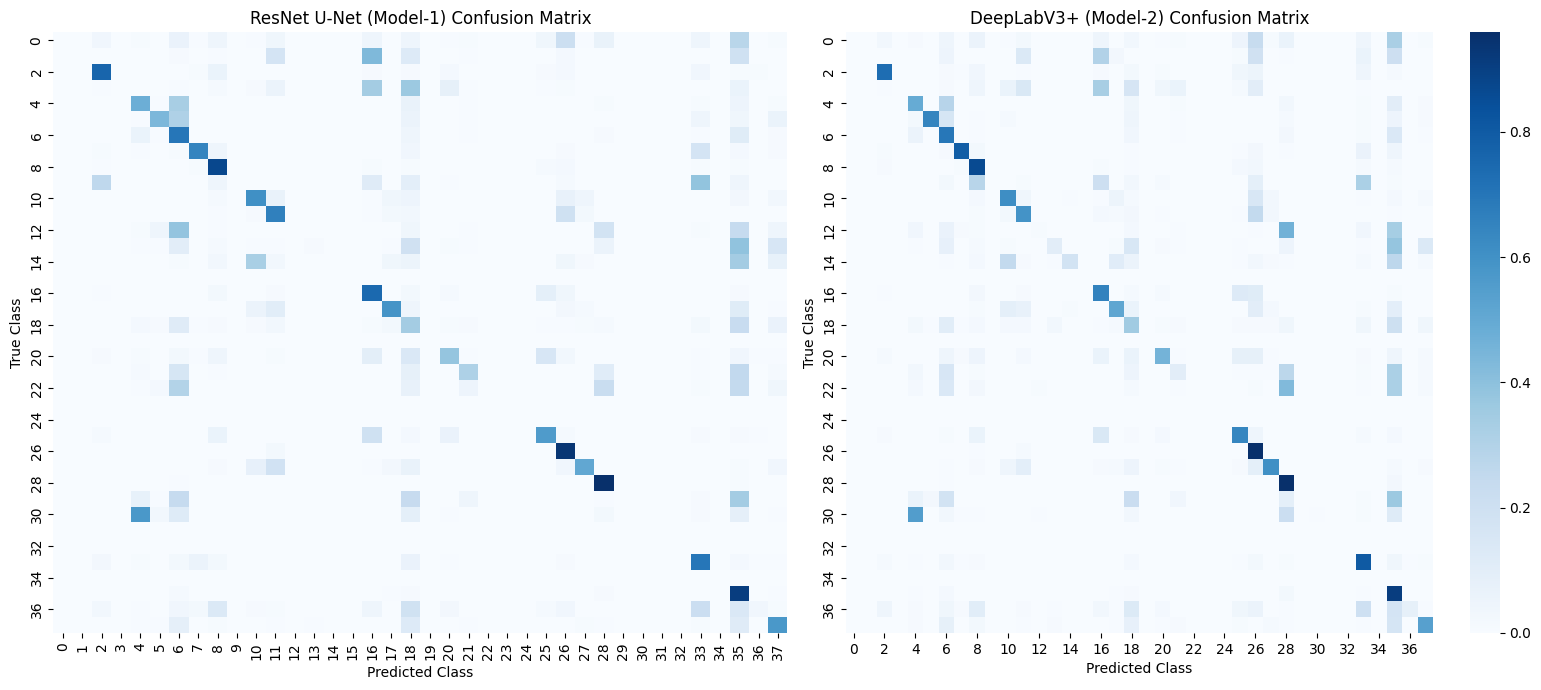

Generating visual comparison plots...


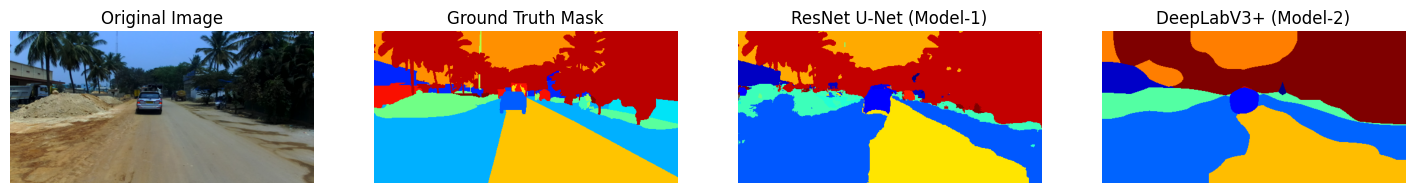

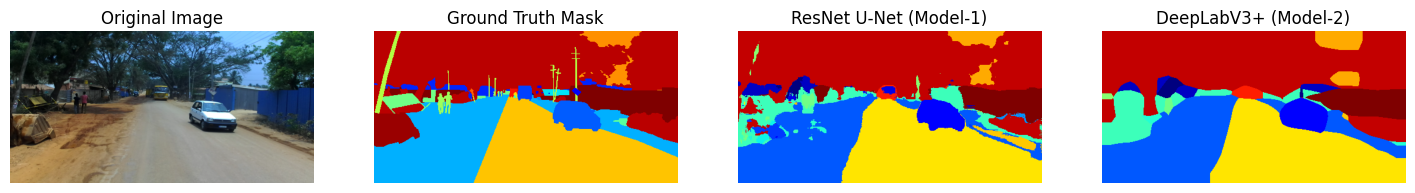

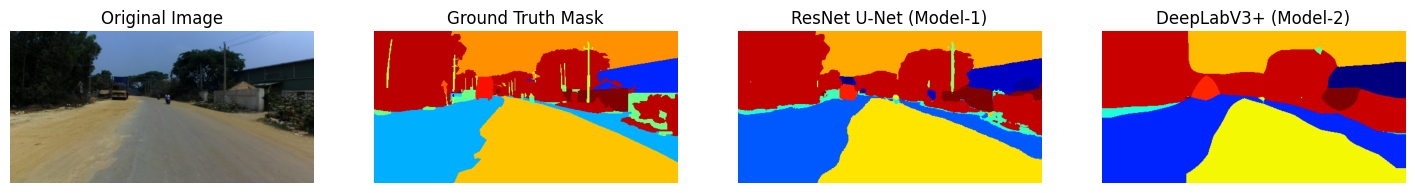

In [55]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Load both saved models from disk
print("Loading saved models...")
unet_model = tf.keras.models.load_model('unet_idd_90.keras', compile=False)
deeplab_model = tf.keras.models.load_model('deeplab_idd_90.keras', compile=False)

# 2. Compute Confusion Matrices across the test dataset
cm_unet = np.zeros((38, 38), dtype=np.int64)
cm_deeplab = np.zeros((38, 38), dtype=np.int64)

print("Evaluating models on test dataset for confusion matrices...")
for images, true_masks in test_dataset:
    # Generate predictions
    unet_preds = unet_model.predict(images, verbose=0)
    unet_pred_masks = np.argmax(unet_preds, axis=-1)
    
    deeplab_preds = deeplab_model.predict(images, verbose=0)
    deeplab_pred_masks = np.argmax(deeplab_preds, axis=-1)
    
    y_true = true_masks.numpy().flatten()
    
    cm_unet += confusion_matrix(y_true, unet_pred_masks.flatten(), labels=range(38))
    cm_deeplab += confusion_matrix(y_true, deeplab_pred_masks.flatten(), labels=range(38))

# Normalize matrices
cm_unet_norm = cm_unet.astype('float') / (cm_unet.sum(axis=1, keepdims=True) + 1e-7)
cm_deepl_norm = cm_deeplab.astype('float') / (cm_deeplab.sum(axis=1, keepdims=True) + 1e-7)

# Plot Confusion Matrices Side-by-Side
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.heatmap(cm_unet_norm, cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title('ResNet U-Net (Model-1) Confusion Matrix')
axes[0].set_xlabel('Predicted Class')
axes[0].set_ylabel('True Class')

sns.heatmap(cm_deepl_norm, cmap='Blues', ax=axes[1])
axes[1].set_title('DeepLabV3+ (Model-2) Confusion Matrix')
axes[1].set_xlabel('Predicted Class')
axes[1].set_ylabel('True Class')

plt.tight_layout()
plt.show()

# 3. Side-by-Side Visual Predictions Comparison
print("Generating visual comparison plots...")
for images, true_masks in test_dataset.take(1):
    unet_preds = unet_model.predict(images, verbose=0)
    unet_pred_masks = np.argmax(unet_preds, axis=-1)
    
    deeplab_preds = deeplab_model.predict(images, verbose=0)
    deeplab_pred_masks = np.argmax(deeplab_preds, axis=-1)
    
    for i in range(min(3, len(images))):
        plt.figure(figsize=(18, 5))
        
        # Original Image
        plt.subplot(1, 4, 1)
        plt.imshow(images[i])
        plt.title('Original Image')
        plt.axis('off')
        
        # Ground Truth Mask
        plt.subplot(1, 4, 2)
        plt.imshow(true_masks[i].numpy().squeeze(), cmap='jet')
        plt.title('Ground Truth Mask')
        plt.axis('off')
        
        # ResNet U-Net Prediction
        plt.subplot(1, 4, 3)
        plt.imshow(unet_pred_masks[i], cmap='jet')
        plt.title('ResNet U-Net (Model-1)')
        plt.axis('off')
        
        # DeepLabV3+ Prediction
        plt.subplot(1, 4, 4)
        plt.imshow(deeplab_pred_masks[i], cmap='jet')
        plt.title('DeepLabV3+ (Model-2)')
        plt.axis('off')
        
        plt.show()

# Fine-Tuning